# Classification Algorithms – Titanic Dataset

## Study Material + Python Mini Project

**Topics:** Logistic Regression, Decision Trees, Random Forests, Support Vector Machines (SVM), and K-Nearest Neighbours (KNN).

### Project goal
Predict whether a Titanic passenger survived (`survived = 1`) or did not survive (`survived = 0`).

### Learning objectives
- Understand the basic idea of five common classification algorithms.
- Prepare the Titanic dataset for machine learning.
- Handle missing values and categorical variables.
- Use train-test split and preprocessing pipelines.
- Train and evaluate five models.
- Compare Accuracy, Precision, Recall, F1-score and ROC-AUC.
- Perform basic hyperparameter tuning.


# 1. Classification – Basic Idea

Classification is supervised learning where the target is a category/class. In this project the target is binary:

- `1` = Survived
- `0` = Did not survive

The model learns a relationship between input features `X` and target `y`, then predicts the class of new observations.


# 2. Logistic Regression

Logistic Regression estimates the probability of a class. For binary classification it commonly uses the sigmoid function:

**p = 1 / (1 + e^(-z))**

where `z = b0 + b1x1 + ... + bpxp`.

**Advantages:** simple, fast, interpretable, useful as a baseline.

**Limitations:** a basic Logistic Regression model represents a linear decision boundary and may struggle with strongly non-linear patterns.

**Important parameter:** `C` controls the strength of regularization (smaller `C` means stronger regularization).


# 3. Decision Tree

A Decision Tree repeatedly splits observations using feature-based rules and ends in leaf nodes containing predictions.

**Important parameters:**
- `max_depth` – limits tree depth.
- `min_samples_split` – minimum observations required to split a node.
- `min_samples_leaf` – minimum observations in a leaf.
- `criterion` – split quality measure such as Gini impurity or entropy.

**Advantages:** easy to understand, handles non-linear relationships, and does not require feature scaling.

**Limitation:** an unrestricted tree can overfit.


# 4. Random Forest

Random Forest is an ensemble of decision trees. Trees are trained on bootstrap samples and the forest combines their predictions. This randomness and averaging can reduce the variance of individual trees.

**Important parameters:** `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, and `max_features`.

**Advantages:** captures non-linear relationships and is generally more stable than a single tree. Feature scaling is not normally required.

**Limitation:** less interpretable than a small single tree and can use more computation.


# 5. Support Vector Machine (SVM)

SVM searches for a separating boundary with a large margin between classes. Kernel functions can model non-linear boundaries. Common kernels include linear, polynomial and RBF.

**Important parameters:**
- `C` – controls the trade-off between margin size and training errors.
- `kernel` – type of decision function.
- `gamma` – controls the influence of individual observations for kernels such as RBF.

SVM is sensitive to feature scale, so scaling is generally important.


# 6. K-Nearest Neighbours (KNN)

KNN predicts a new observation from the classes of its nearest training observations. With `k = 5`, for example, the five nearest observations vote on the class.

**Important parameter:** `n_neighbors` (`k`).

A small `k` can be sensitive to noise; a larger `k` generally produces smoother decision boundaries. The best value depends on the dataset.

KNN is sensitive to feature scaling and can become less effective in high-dimensional spaces.


# 7. Quick Comparison

| Model | Main idea | Scaling | Non-linear patterns | Interpretability |
|---|---|---|---|---|
| Logistic Regression | Probability from linear model | Useful | Limited | High |
| Decision Tree | Rule-based splits | Not required | Yes | High |
| Random Forest | Many decision trees | Not required | Yes | Medium |
| SVM | Maximum-margin boundary | Important | Yes, with kernels | Medium/Low |
| KNN | Majority vote of neighbours | Important | Yes | Medium |

There is no universal best classifier; performance depends on data, preprocessing, metric and tuning.


# 8. Model Evaluation

For binary classification:

- **TP:** predicted 1, actual 1
- **TN:** predicted 0, actual 0
- **FP:** predicted 1, actual 0
- **FN:** predicted 0, actual 1

**Accuracy** = (TP + TN) / Total

**Precision** = TP / (TP + FP)

**Recall** = TP / (TP + FN)

**F1-score** = harmonic mean of Precision and Recall.

**ROC-AUC** measures how well the model's scores/probabilities distinguish the two classes across classification thresholds.

Accuracy should not be used alone when class balance or error costs make other metrics important.


# 9. Titanic Mini Project – Workflow

1. Load Titanic data.
2. Explore missing values and variables.
3. Select useful features.
4. Split into train and test sets.
5. Impute missing values.
6. One-hot encode categorical features.
7. Scale numeric features in the shared pipeline.
8. Train Logistic Regression, Decision Tree, Random Forest, SVM and KNN.
9. Evaluate and compare models.
10. Tune Random Forest with GridSearchCV.


In [1]:
# If needed:
# pip install pandas numpy seaborn scikit-learn matplotlib

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)


In [2]:
# Load the Titanic dataset
df = sns.load_dataset("titanic")

print(df.head())
print("Shape:", df.shape)
print(df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())


   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
Shape: (891, 15)
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Missing values:
survived         0
pclass           0
s

In [3]:
# Select features and target
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X = df[features]
y = df["survived"]

print(X.head())
print(y.head())


   pclass     sex   age  sibsp  parch     fare embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


In [4]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (712, 7)
Testing: (179, 7)


In [5]:
# Preprocessing
numeric_features = ["pclass", "age", "sibsp", "parch", "fare"]
categorical_features = ["sex", "embarked"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


# 10. Train the Five Models

The following cells use the same preprocessing pipeline so that missing values, categorical variables and numeric scaling are handled consistently.


In [6]:
# 1. Logistic Regression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])
logistic_model.fit(X_train, y_train)
y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]


In [7]:
# 2. Decision Tree
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=4,criterion='gini', random_state=42))
])
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)
y_prob_tree = tree_model.predict_proba(X_test)[:, 1]


In [8]:
# 3. Random Forest
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=200, random_state=42))
])
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]


In [9]:
# 4. SVM
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVC(kernel="rbf", C=1.0, probability=True, random_state=42))
])
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)
y_prob_svm = svm_model.predict_proba(X_test)[:, 1]


c:\Users\aamir\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [10]:
# 5. KNN
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5))
])
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]


In [11]:
# Evaluation function
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

results = [
    evaluate_model("Logistic Regression", y_test, y_pred_lr, y_prob_lr),
    evaluate_model("Decision Tree", y_test, y_pred_tree, y_prob_tree),
    evaluate_model("Random Forest", y_test, y_pred_rf, y_prob_rf),
    evaluate_model("SVM", y_test, y_pred_svm, y_prob_svm),
    evaluate_model("KNN", y_test, y_pred_knn, y_prob_knn)
]

results_df = pd.DataFrame(results)
print(results_df.round(4))


                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.8045     0.7931  0.6667  0.7244   0.8437
1        Decision Tree    0.7933     0.8636  0.5507  0.6726   0.8292
2        Random Forest    0.8156     0.8000  0.6957  0.7442   0.8300
3                  SVM    0.8156     0.8214  0.6667  0.7360   0.8401
4                  KNN    0.8156     0.8000  0.6957  0.7442   0.8495


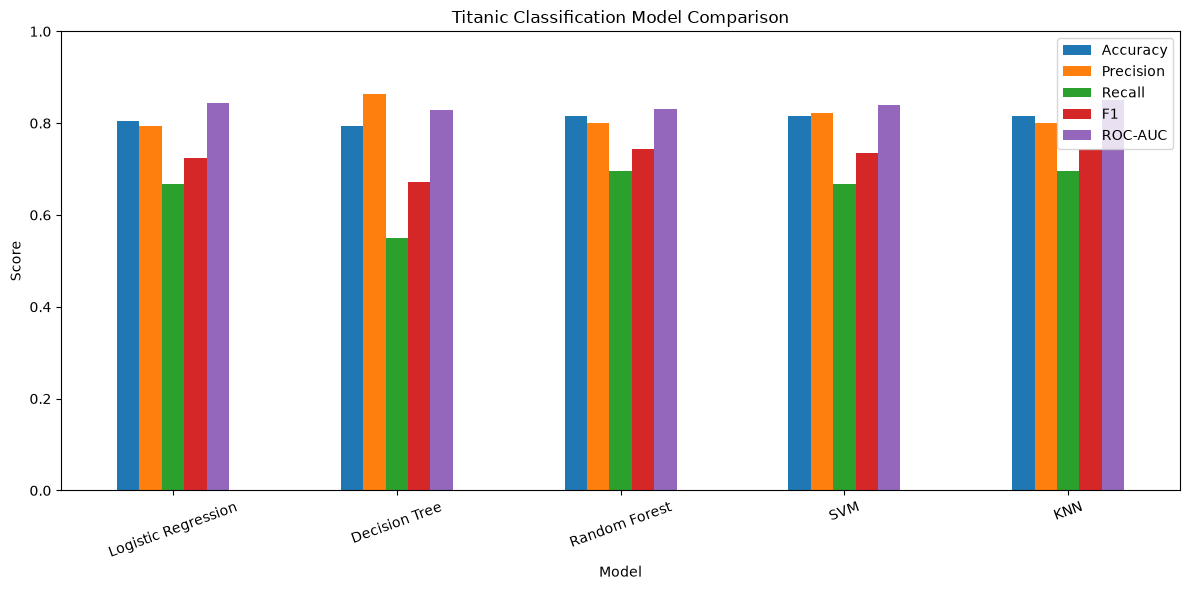

In [17]:
# Plot model comparison
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Titanic Classification Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


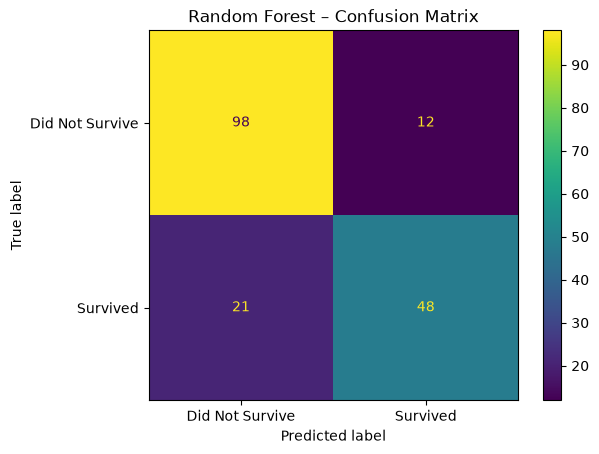

                 precision    recall  f1-score   support

Did Not Survive       0.82      0.89      0.86       110
       Survived       0.80      0.70      0.74        69

       accuracy                           0.82       179
      macro avg       0.81      0.79      0.80       179
   weighted avg       0.81      0.82      0.81       179



In [19]:
# Confusion matrix – Random Forest
cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)
disp.plot()
plt.title("Random Forest – Confusion Matrix")
plt.show()

print(classification_report(
    y_test, y_pred_rf,
    target_names=["Did Not Survive", "Survived"]
))


# 11. Hyperparameter Tuning – Random Forest

GridSearchCV evaluates parameter combinations using cross-validation. Here we tune the number and depth of trees and the minimum samples needed to split a node.


In [20]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [3, 5, 8],
    "model__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    rf_pipeline, param_grid=param_grid,
    cv=5, scoring="r2"
)

grid_search.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [3, 5, ...], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, d

In [15]:
from sklearn.metrics import r2_score

In [16]:
print("Best parameters:")
print(grid_search.best_params_)
print("Best CV R2:", grid_search.best_score_)

best_rf = grid_search.best_estimator_
y_pred_best = best_rf.predict(X_test)
y_prob_best = best_rf.predict_proba(X_test)[:, 1]

print("Test Accuracy:", accuracy_score(y_test, y_pred_best))
print("Test R2:", r2_score(y_test, y_pred_best))
print("Test ROC-AUC:", roc_auc_score(y_test, y_prob_best))

Best parameters:
{'model__max_depth': 5, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best CV R2: 0.2517670962498548
Test Accuracy: 0.8156424581005587
Test R2: 0.22173913043478266
Test ROC-AUC: 0.8431488801054018


In [21]:
grid_search.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['pclass','sex','age',...,'parch','fare','embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns tha

# 12. Quick Revision

**Logistic Regression:** probability-based, simple and interpretable baseline.

**Decision Tree:** rule-based splits; easy to explain; can overfit.

**Random Forest:** many randomized decision trees; generally reduces variance.

**SVM:** maximum-margin classifier; kernels allow non-linear boundaries; scaling is important.

**KNN:** predicts from nearby observations; scaling is important and `k` controls smoothness.

### Practice questions
1. Why is Logistic Regression used for classification?
2. What does the sigmoid function do?
3. Why can a Decision Tree overfit?
4. What does `max_depth` control?
5. How does Random Forest reduce the weaknesses of one tree?
6. What is the role of `C` in SVM?
7. Why is scaling important for SVM and KNN?
8. What does `k` mean in KNN?
9. Explain precision and recall.
10. When would F1-score be more informative than accuracy?
11. Why do we one-hot encode `sex` and `embarked`?
12. Why should preprocessing be learned from training data only?
13. What is ROC-AUC?
14. What is cross-validation?
15. What is hyperparameter tuning?
